<a href="https://colab.research.google.com/github/OJB-Quantum/Notebooks-for-Ideas/blob/main/CuDSS_Micromagnetic_Standard_Problem_5_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Authored by Onri Jay Benally (2026)

Open Access (CC-BY-4.0)

# cuDSS micromagnetics: Standard Problem 5

## First-principles primer

Micromagnetics represents a ferromagnet through a continuous unit magnetization field, whereby exchange favors neighboring alignment while the demagnetizing field favors flux closure and promotes a vortex within this thin permalloy square. Current transfers spin angular momentum to the changing texture, which directly drives vortex motion while Gilbert damping dissipates magnetic energy and the sample boundaries constrain the displaced core [1, 2]. This notebook evolves the three-dimensional magnetization at zero temperature, whereby each cell holds three spin components and an exchange-implicit tangent-plane equation supplies a sparse system for cuDSS at every step [3, 4].

Historical work by Landau and Lifshitz supplies the precession-and-damping framework, Gilbert supplies its derivative-dependent damping form, and Zhang and Li extend this framework through current-induced spin torque. Najafi and colleagues propose the vortex benchmark in 2009, while Newell and colleagues supply the finite-cell demagnetizing tensor and Alouges develops the tangent-plane approach used here through a finite-difference adaptation [1–4].

| Term | Full name or origin | Role here |
|---|---|---|
| cuDSS | NVIDIA CUDA Direct Sparse Solver; CUDA derives from Compute Unified Device Architecture | GPU sparse direct solve of each tangent-plane update |
| CuPy | CUDA-oriented NumPy-compatible array library | GPU arrays, sparse exchange products, tensor operations, and FFTs |
| LLG | Landau–Lifshitz–Gilbert equation | Magnetization dynamics |
| STT | Spin-transfer torque | Zhang–Li current-driven terms |
| FFT | Fast Fourier transform | Isolated-sample magnetostatic convolution |
| CSR | Compressed sparse row | Sparse tangent-plane matrix format |
| IMEX | Implicit–explicit, a compound of the two numerical treatments | Implicit exchange with explicit demagnetizing field and STT |
| Permalloy | Historical name derived from a highly permeable nickel–iron alloy | Soft-magnetic benchmark material, represented through its specified constants |
| Vortex chirality/ polarity | Circulation direction/ core direction | Counterclockwise circulation and a positive-z core by default |

## Physical specification and symbols

| Symbol | Meaning | Default value or regime |
|---|---|---|
| $\mathbf m=\mathbf M/M_s$ | Unit magnetization vector; $\mathbf M$ is magnetization | $\lvert\mathbf m\rvert=1$ at each cell |
| $L_x,L_y,L_z$ | Cuboid dimensions | $100,100,10\ \mathrm{nm}$ |
| $M_s$ | Saturation magnetization | $8.0\times10^5\ \mathrm{A\,m^{-1}}$ |
| $A$ | Exchange stiffness | $1.3\times10^{-11}\ \mathrm{J\,m^{-1}}$ |
| $\mu_0$ | Vacuum permeability | $4\pi\times10^{-7}\ \mathrm{H\,m^{-1}}$ |
| $\gamma_G$ | Positive Gilbert gyromagnetic coefficient for an $H$ field in A/m | $2.211\times10^5\ \mathrm{m\,A^{-1}\,s^{-1}}$ |
| $\alpha$ | Gilbert damping | $0.1$ during dynamics; $1$ during relaxation |
| $\xi$ | Nonadiabatic torque coefficient, also called $\beta$ | $0.05$; other standard cases are $0,0.1,0.5$ |
| $P,j_x$ | Spin polarization and conventional current density | $1$ and $+10^{12}\ \mathrm{A\,m^{-2}}$ |
| $\mu_B,e$ | Bohr magneton and positive elementary charge | $9.2740100657\times10^{-24}\ \mathrm{J\,T^{-1}}$, $1.602176634\times10^{-19}\ \mathrm C$ |
| $u_x$ | Signed coefficient of the $+u_x\partial_x\mathbf m$ Gilbert torque | Approximately $-72.17\ \mathrm{m\,s^{-1}}$ for $\xi=0.05$ |
| $\mathbf g$ | Projected directional derivative $P_{\mathbf m}(u_x\partial_x\mathbf m)$ | Tangential spin-transport rate, in $\mathrm{s^{-1}}$ |
| $P_{\mathbf m} = I-\mathbf m\mathbf m^\mathsf T$ | Orthogonal tangent-plane projector | Acts independently at each cell |
| $C_{\rm ex} = 2A/(\mu_0M_s)$ | Exchange-field coefficient | Multiplies the discrete Laplacian |
| $\Delta_h$ | Nearest-neighbor discrete Laplacian | Free exchange boundary; replicated edge ghosts for the STT derivative |
| $h,\Delta t,\theta$ | Cubic cell side, time step, implicit exchange weight | $5\ \mathrm{nm}$, $0.25\ \mathrm{ps}$, $1$ |
| $\ell_{\rm ex}$ | Magnetostatic exchange length | Approximately $5.69\ \mathrm{nm}$ |
| $T_i$ | $3\times2$ right-handed tangent frame at cell $i$ | Columns orthogonal to $\mathbf m_i$ |
| $J$ | Two-component cross-product operator | $J_{12}=-1$, $J_{21}=1$, diagonal entries zero |
| $\mathbf w,\mathbf q$ | Tangent increment and its two frame coefficients | $\mathbf w_i=T_i\mathbf q_i$ |
| $\Delta t_{\rm relax,min}$ | Minimum accepted relaxation trial size | $0.001\ \mathrm{ps}$ |
| $r_{\rm grow}$ | Maximum trial-to-previous angular-rate ratio during relaxation | $2$; a larger increase rejects the trial |
| $\epsilon_{E,r},\epsilon_{E,a}$ | Relative and absolute zero-current energy tolerances | $10^{-10}$ and $10^{-30}\ \mathrm J$ |
| $N$ | Number of magnetic cells | $800$ by default; the sparse system holds $2N$ unknowns |

In the code, the default mesh uses twenty cells along each lateral direction and two through the thickness, which enables an accessible first run while every figure reports the selected cell size. Spatial refinement through `cell_nm=2.5` or `cell_nm=2.0` resolves the vortex core more finely, and separate time-step refinement measures the numerical damping introduced by this first-order update. Permalloy's small crystalline anisotropy justifies the benchmark's exchange-plus-demagnetizing energy, while zero applied field, zero thermal noise, and the prescribed current define the physical model [1].

## Governing equations

The signed current convention matches the documented Zhang–Li torque, whereby a positive conventional current along x yields a negative $u_x$ and the factor $1+\xi^2$ fixes the small historical current-normalization discrepancy. Gilbert and Landau–Lifshitz gyromagnetic coefficients satisfy $\gamma_{\rm LL}=\gamma_G/(1+\alpha^2)$, so comparison with another solver requires the same coefficient convention as well as matching polarity, chirality, mesh, and initial equilibrium [1, 2].

$$
u_x=-\frac{P\mu_Bj_x}{eM_s(1+\xi^2)},\qquad \ell_{\rm ex}=\sqrt{\frac{2A}{\mu_0M_s^2}}.
$$

$$
\partial_t\mathbf m=-\gamma_G\mathbf m\times\mathbf H_{\rm eff}+\alpha\mathbf m\times\partial_t\mathbf m+\mathbf g-\xi\mathbf m\times\mathbf g.
$$

$$
\mathbf H_{\rm eff}=C_{\rm ex}\Delta_h\mathbf m+\mathbf H_d,\qquad \mathbf H_{d,i}=-M_s\sum_j\mathsf N_{i-j}\mathbf m_j.
$$

Here $\mathsf N_{i-j}$ holds the volume-averaged Newell tensor between rectangular cells, including the finite self term, while zero padding makes the FFT evaluate an isolated-sample convolution. Long-double arithmetic builds this geometry-dependent tensor once on the CPU to reduce cancellation, after which CuPy evaluates the demagnetizing field on the GPU at every time step [3].

$$
(\alpha I+\mathbf m^n\times)\mathbf w-\gamma_GC_{\rm ex}\theta\Delta t\,P_{\mathbf m^n}\Delta_h\mathbf w=\Delta t\left[\gamma_GP_{\mathbf m^n}\mathbf H_{\rm eff}^n+\mathbf m^n\times\mathbf g^n+\xi\mathbf g^n\right].
$$

$$
\mathcal A_{ia,jb}=\delta_{ij}(\alpha\delta_{ab}+J_{ab})-\gamma_GC_{\rm ex}\theta\Delta t\,(\Delta_h)_{ij}(T_{ia}\cdot T_{jb}),\qquad \mathcal A\mathbf q=\mathbf b.
$$

$$
\mathbf m_i^{n+1}=\frac{\mathbf m_i^n+T_i\mathbf q_i}{|\mathbf m_i^n+T_i\mathbf q_i|},\qquad E_{\rm ex}=-Ah^3\sum_i\mathbf m_i\cdot\Delta_h\mathbf m_i,\qquad E_d=-\frac{\mu_0M_sh^3}{2}\sum_i\mathbf m_i\cdot\mathbf H_{d,i}.
$$

For fixed spatial resolution, the first-order tangent-plane method has global time error $\propto\Delta t$ in its smooth resolved regime, while centered interior spatial differences have local error $\propto h^2$. Current supplies energy during the driven stage, so total magnetic energy need not decrease monotonically; relaxation instead applies zero current until the unsplit physical angular rate falls below its stated tolerance.

## Colab execution

Select a GPU runtime and execute the cells in order.

## CUDA 12 environment

In [1]:
# --- Environment Controls ---
INSTALL_PACKAGES = True
VERBOSE_LIBRARY_PATHS = True
REQUIRED_PACKAGES = (
    'cupy-cuda12x[ctk]==14.2.0',
    'nvidia-cudss-cu12==1.0.0.35',
    'nvidia-cuda-runtime-cu12==12.9.*',
    'nvidia-cuda-nvrtc-cu12==12.9.*',
    'nvidia-cuda-nvcc-cu12==12.9.*',
    'numpy', 'scipy', 'matplotlib', 'psutil', 'ipywidgets',
)

# --- Standard-Library Bootstrap ---
import ctypes
import hashlib
import importlib.metadata as metadata
import os
from pathlib import Path
import re
import shutil
import subprocess
import sys
import tempfile

_CUDA_HANDLES = []
_CUDA_LIBRARIES = {}

In [ ]:
def package_snapshot():
    """Record packages whose native libraries might already be mapped."""
    return {
        d.metadata.get('Name', '').lower(): d.version
        for d in metadata.distributions()
        if d.metadata.get('Name', '').lower().startswith(('cupy', 'nvidia-', 'cuda-'))
        or d.metadata.get('Name', '').lower() in ('numpy', 'scipy', 'matplotlib')
    }


def gpu_libraries_are_loaded():
    """Detect native CUDA mappings without loading a CUDA library."""
    maps = Path('/proc/self/maps')
    if maps.exists():
        text = maps.read_text(errors='replace')
        return bool(re.search(r'/lib(?:cudart|cublas|cufft|cusparse|cudss|nvrtc)\.', text))
    return any(n == 'cupy' or n.startswith('cupy.') for n in sys.modules)


def bootstrap_environment():
    """Install through uv in this interpreter and reject stale native imports."""
    before = package_snapshot()
    loaded_gpu = gpu_libraries_are_loaded()
    loaded_python = {name: name in sys.modules for name in ('numpy', 'scipy', 'matplotlib')}
    conflicts = sorted(name for name in before
                       if name == 'cupy' or name.startswith('cupy-cuda')
                       if name != 'cupy-cuda12x')
    if INSTALL_PACKAGES:
        uv = shutil.which('uv')
        if uv is None:
            raise RuntimeError('Install uv before this cell: %pip install uv')
        if conflicts:
            if loaded_gpu:
                raise RuntimeError('Restart the Colab session, then run this setup cell first; '
                                   'a conflicting CuPy stack is already loaded.')
            subprocess.run([uv, 'pip', 'uninstall', '--python', sys.executable,
                            *conflicts], check=True)
        subprocess.run([uv, 'pip', 'install', '--python', sys.executable,
                        *REQUIRED_PACKAGES], check=True)
    after = package_snapshot()
    changed = {name for name in before.keys() | after.keys()
               if before.get(name) != after.get(name)}
    native_changed = any(name.startswith(('cupy', 'nvidia-', 'cuda-')) for name in changed)
    stale_python = any(loaded_python[name] and name in changed for name in loaded_python)
    if (loaded_gpu and native_changed) or stale_python:
        raise RuntimeError('Packages are installed. Restart the Colab session, then run all '
                           'cells from the top so the process loads the installed libraries.')
    remaining = [name for name in after if name == 'cupy' or name.startswith('cupy-cuda')]
    if remaining != ['cupy-cuda12x']:
        raise RuntimeError(f'Expected one CuPy CUDA 12 distribution; found {remaining}.')
    print('CUDA 12 package setup is ready for native-library checks.')


def wheel_paths(distribution_name):
    """Use wheel metadata first and bounded NVIDIA-directory fallbacks second."""
    try:
        dist = metadata.distribution(distribution_name)
    except metadata.PackageNotFoundError:
        return [], []
    root = Path(dist.locate_file(''))
    files = [Path(dist.locate_file(f)) for f in dist.files or ()]
    files = [p for p in files if p.exists()]
    components = {
        'nvidia-cudss-cu12': ('cudss', 'cu12'),
        'nvidia-cuda-runtime-cu12': ('cuda_runtime', 'cu12'),
        'nvidia-cuda-nvcc-cu12': ('cuda_nvcc', 'cu12'),
    }
    roots = [root / 'nvidia' / c for c in components.get(distribution_name, ())]
    for folder in roots:
        if folder.is_dir():
            files.extend(p for p in folder.rglob('*')
                         if p.is_file() and ('.so' in p.name or p.suffix == '.h'))
    return sorted(set(files)), roots


def nvidia_library_inventory():
    """Collect CUDA 12 wheel libraries and cuDSS layout candidates."""
    paths = set()
    roots = []
    for dist in metadata.distributions():
        name = dist.metadata.get('Name', '').lower()
        if name.startswith('nvidia-') and name.endswith('-cu12'):
            files, folders = wheel_paths(name)
            paths.update(p for p in files if '.so' in p.name)
            roots.extend(folders)
    cudss_files, cudss_roots = wheel_paths('nvidia-cudss-cu12')
    paths.update(p for p in cudss_files if '.so' in p.name)
    return sorted(paths), cudss_files, sorted(set(roots + cudss_roots))


def load_cuda12_libraries():
    """Load wheel-provided cuFFT and sparse-solver dependencies before CuPy."""
    paths, cudss_files, roots = nvidia_library_inventory()
    if VERBOSE_LIBRARY_PATHS:
        print('cuDSS search roots:', ', '.join(str(p) for p in roots if p.exists()))
    prefixes = (
        'libcudart.so', 'libnvJitLink.so', 'libcublasLt.so', 'libcublas.so',
        'libcufft.so', 'libcurand.so', 'libcusparse.so', 'libcusolver.so',
        'libnvrtc-builtins.so', 'libnvrtc.so', 'libcudss.so',
    )
    for prefix in prefixes:
        matches = sorted((p for p in paths if p.name.startswith(prefix)),
                         key=lambda p: (len(p.name), str(p)))
        if not matches:
            raise RuntimeError(f'Missing {prefix} in the CUDA 12 wheels. '
                               'Run the environment setup cell before importing CuPy.')
        path = matches[0].resolve()
        if prefix not in _CUDA_LIBRARIES:
            try:
                handle = ctypes.CDLL(str(path), mode=ctypes.RTLD_GLOBAL)
            except OSError as exc:
                raise RuntimeError(f'Unable to load {path}: {exc}') from exc
            _CUDA_HANDLES.append(handle)
            _CUDA_LIBRARIES[prefix] = path
        if VERBOSE_LIBRARY_PATHS:
            print(f'{prefix}: {_CUDA_LIBRARIES[prefix]}')
    return cudss_files


def bridge_include_directories(cudss_files):
    """Locate matching CUDA 12 runtime and compiler headers."""
    headers = sorted(p for p in cudss_files if p.name == 'cudss.h')
    if not headers:
        raise RuntimeError('cudss.h is absent from the installed cuDSS wheel.')
    includes = [headers[0].parent]
    for name in ('nvidia-cuda-runtime-cu12', 'nvidia-cuda-nvcc-cu12'):
        files, _ = wheel_paths(name)
        includes.extend(p.parent for p in files if p.name == 'cuda_runtime_api.h')
        includes.extend(p.parent.parent for p in files
                        if p.name == 'host_config.h' and p.parent.name == 'crt')
    includes = list(dict.fromkeys(includes))
    if not any((p / 'cuda_runtime_api.h').exists() for p in includes):
        raise RuntimeError('CUDA 12 runtime headers are missing from the setup.')
    if not any((p / 'crt/host_config.h').exists() for p in includes):
        raise RuntimeError('CUDA 12 compiler headers are missing from the setup.')
    return includes


def child_library_environment():
    """Set native search paths before starting a compiler or probe process."""
    env = os.environ.copy()
    folders = list(dict.fromkeys(str(p.parent) for p in _CUDA_LIBRARIES.values()))
    existing = env.get('LD_LIBRARY_PATH', '')
    if existing:
        folders.append(existing)
    env['LD_LIBRARY_PATH'] = os.pathsep.join(folders)
    return env


def configure_cuda12_headers():
    """Bind CuPy's cudart-header lookup to the verified CUDA 12 wheel."""
    import cuda.pathfinder as pathfinder

    runtime_version = metadata.version('nvidia-cuda-runtime-cu12')
    nvrtc_version = metadata.version('nvidia-cuda-nvrtc-cu12')
    if runtime_version.split('.')[:2] != nvrtc_version.split('.')[:2]:
        raise RuntimeError('The CUDA runtime headers and NVRTC must use the same '
                           'major and minor version. Run setup before importing CuPy.')
    files, _ = wheel_paths('nvidia-cuda-runtime-cu12')
    candidates = sorted({p.parent for p in files if p.name == 'cuda_runtime_api.h'})
    selected = None
    header_version = None
    for folder in candidates:
        cuda_header = folder / 'cuda.h'
        if not cuda_header.is_file():
            continue
        match = re.search(r'^\s*#\s*define\s+CUDA_VERSION\s+(\d+)',
                          cuda_header.read_text(errors='replace'), re.MULTILINE)
        if match and 12000 <= int(match.group(1)) < 13000:
            selected, header_version = folder.resolve(), int(match.group(1))
            break
    if selected is None:
        raise RuntimeError('A verified CUDA 12 cuda.h and runtime-header directory '
                           'are required before importing CuPy.')
    original = pathfinder.find_nvidia_header_directory
    previous = getattr(original, '_sp5_cuda12_headers', None)
    if 'cupy' in sys.modules and previous != str(selected):
        raise RuntimeError('Restart the Colab session, then run all cells from the top. '
                           'CuPy has already cached its earlier CUDA-header selection.')
    if previous is not None:
        original = original._sp5_original

    def find_headers(libname):
        # CuPy 14.2 imports this public function when it first assembles JIT options.
        # Scope the override to cudart; other products keep their normal lookup.
        if libname == 'cudart':
            return str(selected)
        return original(libname)

    find_headers._sp5_cuda12_headers = str(selected)
    find_headers._sp5_original = original
    pathfinder.find_nvidia_header_directory = find_headers
    print(f'CuPy CUDA runtime headers: {selected} | CUDA_VERSION={header_version}')
    return str(selected), header_version

bootstrap_environment()
CUDA12_FILES = load_cuda12_libraries()
CUDA12_HEADER_DIR, CUDA12_HEADER_VERSION = configure_cuda12_headers()

## Control knobs and imports

In [3]:
"""This script evolves a three-dimensional current-driven permalloy vortex."""

# --- Control Knobs ---
from dataclasses import dataclass, replace


@dataclass(frozen=True)
class Settings:
    """Hold physical, numerical, and display controls in SI units."""

    cell_nm: float = 5.0  # Use 2.5 or 2.0 for spatial refinement.
    dt_ps: float = 0.25
    duration_ns: float = 5.0
    sample_ps: float = 10.0
    relax_dt_ps: float = 0.5
    relax_min_dt_ps: float = 0.001
    relax_max_retries: int = 20
    relax_max_steps: int = 200000
    relax_rate_growth: float = 2.0
    relax_energy_rtol: float = 1e-10
    relax_energy_atol_j: float = 1e-30
    relax_max_ns: float = 5.0
    relax_rate_rad_ns: float = 0.01
    alpha: float = 0.1
    xi: float = 0.05  # Other standard cases: 0.0, 0.1, 0.5.
    current_a_m2: float = 1.0e12  # Conventional charge current along +x.
    polarization: float = 1.0
    ms_a_m: float = 8.0e5
    exchange_j_m: float = 1.3e-11
    gamma_g: float = 2.211e5  # Gilbert coefficient, m/(A s).
    theta: float = 1.0  # Implicit exchange weight.
    length_nm: float = 100.0
    width_nm: float = 100.0
    thickness_nm: float = 10.0
    chirality: int = 1  # +1: counterclockwise, viewed from +z.
    polarity: int = 1  # +1: vortex core points toward +z.
    glyph_stride: int = 1  # Thinning never enlarges arrows.
    glyph_fraction: float = 0.78  # Length relative to one computed cell.
    animation_frames: int = 101
    run_time_refinement: bool = False  # Adds a dt/2 trajectory.
    run_mesh_refinement: bool = False  # Adds a cell/2 trajectory.
    release_gpu_cache_after_run: bool = True


CFG = Settings()

# --- Imports and Display ---
import ctypes
from contextlib import ExitStack
import gc
import importlib.metadata as metadata
import itertools
import json
from pathlib import Path
import shutil
import subprocess
import tempfile
import time
import weakref

import cupy as cp
import cupyx.scipy.sparse as cpx_sparse
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.collections import PolyCollection
import numpy as np
import psutil
from scipy import sparse
from IPython.display import HTML, display

mpl.rcParams.update({
    'figure.dpi': 200,
    'savefig.dpi': 200,
    'font.family': 'DejaVu Sans',
    'font.weight': 'normal',
    'axes.titleweight': 'normal',
    'axes.labelweight': 'normal',
    'animation.embed_limit': 100.0,
})
MU0 = 4.0 * np.pi * 1e-7
MU_B = 9.2740100657e-24
E_CHARGE = 1.602176634e-19


def check_settings(cfg: Settings) -> None:
    """Reject invalid meshes and inconsistent output schedules."""
    positive = (
        cfg.cell_nm, cfg.dt_ps, cfg.duration_ns, cfg.sample_ps,
        cfg.relax_dt_ps, cfg.relax_min_dt_ps, cfg.relax_max_ns,
        cfg.ms_a_m, cfg.exchange_j_m,
    )
    if min(positive) <= 0 or cfg.alpha <= 0:
        raise ValueError('Cell size, times, material values, and alpha must be positive.')
    if not np.isfinite(positive).all() or not np.isfinite(cfg.alpha):
        raise ValueError('Time, cell, material, and damping values must be finite.')
    if cfg.relax_min_dt_ps > cfg.relax_dt_ps or cfg.relax_rate_growth <= 1:
        raise ValueError('The minimum relaxation step must not exceed its initial step; '
                         'the allowed rate-growth factor must exceed one.')
    if cfg.relax_max_retries < 1 or cfg.relax_max_steps < 1:
        raise ValueError('Relaxation retry and accepted-step limits must be positive.')
    if cfg.relax_energy_rtol < 0 or cfg.relax_energy_atol_j < 0:
        raise ValueError('Relaxation energy tolerances must be nonnegative.')
    if not all(isinstance(v, (int, np.integer)) and v > 0 for v in
               (cfg.glyph_stride, cfg.animation_frames, cfg.relax_max_retries,
                cfg.relax_max_steps)):
        raise ValueError('Glyph, animation, and relaxation count controls must be positive integers.')
    other = (cfg.length_nm, cfg.width_nm, cfg.thickness_nm, cfg.gamma_g,
             cfg.xi, cfg.current_a_m2, cfg.polarization, cfg.relax_rate_rad_ns,
             cfg.relax_rate_growth, cfg.relax_energy_rtol, cfg.relax_energy_atol_j)
    if not np.isfinite(other).all() or min(other[:4]) <= 0 or cfg.relax_rate_rad_ns <= 0:
        raise ValueError('Geometry, torque, rate, and tolerance controls must be finite; '
                         'geometry, gamma, and relaxation-rate tolerance must be positive.')
    for length in (cfg.length_nm, cfg.width_nm, cfg.thickness_nm):
        if not np.isclose(length / cfg.cell_nm, round(length / cfg.cell_nm)):
            raise ValueError('The cell size must divide every sample dimension.')
    if min(cfg.length_nm, cfg.width_nm) / cfg.cell_nm < 4:
        raise ValueError('At least four lateral cells are required.')
    if not 0.5 <= cfg.theta <= 1.0:
        raise ValueError('Use an exchange weight between 0.5 and 1.')
    if not 0 < cfg.glyph_fraction <= 0.8 or cfg.glyph_stride < 1:
        raise ValueError('Use a glyph fraction in (0, 0.8] and a positive stride.')
    if cfg.chirality not in (-1, 1) or cfg.polarity not in (-1, 1):
        raise ValueError('Chirality and polarity must be +1 or -1.')
    if not 0 <= cfg.polarization <= 1:
        raise ValueError('Polarization must lie between zero and one.')
    for ratio in (cfg.sample_ps / cfg.dt_ps,
                  cfg.duration_ns * 1000 / cfg.sample_ps):
        if not np.isclose(ratio, round(ratio)):
            raise ValueError('Sampling must divide the duration and contain whole steps.')

## Native cuDSS bridge and solver ownership

In [4]:
# --- Minimal C++ Bridge to the Installed cuDSS C API ---
BRIDGE_SOURCE = r'''
#include <cstdint>
#include <string>
#include <stdexcept>
#include <memory>
#include <cuda_runtime_api.h>
#include <cudss.h>

struct Solver {
    cudssHandle_t handle = nullptr;
    cudssConfig_t config = nullptr;
    cudssData_t data = nullptr;
    cudssMatrix_t A = nullptr, b = nullptr, x = nullptr;
    bool analyzed = false;
    ~Solver() {
        if (A) cudssMatrixDestroy(A);
        if (b) cudssMatrixDestroy(b);
        if (x) cudssMatrixDestroy(x);
        if (data) cudssDataDestroy(handle, data);
        if (config) cudssConfigDestroy(config);
        if (handle) cudssDestroy(handle);
    }
};
static thread_local std::string last_error;
static void check(cudssStatus_t status, const char* where) {
    if (status != CUDSS_STATUS_SUCCESS)
        throw std::runtime_error(std::string(where) + ": cuDSS status " +
                                 std::to_string(static_cast<int>(status)));
}
extern "C" const char* sp5_error() { return last_error.c_str(); }
extern "C" int sp5_create(void** output, int64_t n, int64_t nnz,
    void* offsets, void* columns, void* values, void* b, void* x, void* stream) {
    if (!output) return 1;
    *output = nullptr;
    try {
        last_error.clear();
        auto s = std::make_unique<Solver>();
        check(cudssCreate(&s->handle), "create handle");
        check(cudssSetStream(s->handle, reinterpret_cast<cudaStream_t>(stream)),
              "set stream");
        check(cudssConfigCreate(&s->config), "create config");
        check(cudssDataCreate(s->handle, &s->data), "create data");
        check(cudssMatrixCreateCsr(&s->A, n, n, nnz, offsets, nullptr,
            columns, values, CUDA_R_32I,
#if defined(CUDSS_VERSION_MAJOR) && CUDSS_VERSION_MAJOR >= 1
            CUDA_R_32I,
#endif
            CUDA_R_64F, CUDSS_MTYPE_GENERAL,
            CUDSS_MVIEW_FULL, CUDSS_BASE_ZERO), "create CSR matrix");
        check(cudssMatrixCreateDn(&s->b, n, 1, n, b, CUDA_R_64F,
            CUDSS_LAYOUT_COL_MAJOR), "create RHS");
        check(cudssMatrixCreateDn(&s->x, n, 1, n, x, CUDA_R_64F,
            CUDSS_LAYOUT_COL_MAJOR), "create solution");
        *output = s.release();
        return 0;
    } catch (const std::exception& e) {
        last_error = e.what(); return 1;
    } catch (...) {
        last_error = "Unknown error while creating the cuDSS context"; return 1;
    }
}
extern "C" int sp5_solve(void* context) {
    Solver* s = static_cast<Solver*>(context);
    try {
        if (!s) throw std::runtime_error("The cuDSS context is closed");
        last_error.clear();
        if (!s->analyzed) {
            check(cudssExecute(s->handle, CUDSS_PHASE_ANALYSIS, s->config,
                s->data, s->A, s->x, s->b), "symbolic analysis");
            s->analyzed = true;
        }
        check(cudssExecute(s->handle, CUDSS_PHASE_FACTORIZATION, s->config,
            s->data, s->A, s->x, s->b), "numerical factorization");
        check(cudssExecute(s->handle, CUDSS_PHASE_SOLVE, s->config,
            s->data, s->A, s->x, s->b), "solve");
        return 0;
    } catch (const std::exception& e) {
        last_error = e.what(); return 1;
    } catch (...) {
        last_error = "Unknown error in the cuDSS solve"; return 1;
    }
}
extern "C" void sp5_destroy(void* context) {
    delete static_cast<Solver*>(context);
}
'''


_BRIDGE_CACHE = {}


def build_bridge() -> ctypes.CDLL:
    """Check loadable wheel libraries and compile the installed cuDSS API."""
    files = load_cuda12_libraries()
    includes = bridge_include_directories(files)
    library = _CUDA_LIBRARIES['libcudss.so']
    compiler = shutil.which('g++')
    if compiler is None:
        raise RuntimeError('g++ is required to build the host-side cuDSS bridge.')
    signature = BRIDGE_SOURCE + str(library) + metadata.version('nvidia-cudss-cu12')
    signature += ''.join(str(p) + str(p.stat().st_mtime_ns) for p in files
                         if p.name in ('cudss.h', 'cudss_data_types.h'))
    key = hashlib.sha256(signature.encode()).hexdigest()
    if key in _BRIDGE_CACHE:
        return _BRIDGE_CACHE[key]
    folder = tempfile.TemporaryDirectory(prefix='sp5_cudss_')
    source = Path(folder.name) / 'bridge.cpp'
    target = Path(folder.name) / 'bridge.so'
    try:
        source.write_text(BRIDGE_SOURCE)
        command = [compiler, '-O2', '-std=c++17', '-shared', '-fPIC', str(source)]
        command += ['-I' + str(p) for p in includes]
        command += [str(library), '-Wl,-rpath,' + str(library.parent),
                    '-o', str(target)]
        result = subprocess.run(command, capture_output=True, text=True,
                                env=child_library_environment(), timeout=120)
        if result.returncode:
            raise RuntimeError('C++ bridge build failed:\n' + result.stderr)
        lib = ctypes.CDLL(str(target))
        ptr, i64 = ctypes.c_void_p, ctypes.c_int64
        lib.sp5_create.argtypes = [ctypes.POINTER(ptr), i64, i64] + [ptr] * 6
        lib.sp5_create.restype = ctypes.c_int
        lib.sp5_solve.argtypes, lib.sp5_solve.restype = [ptr], ctypes.c_int
        lib.sp5_destroy.argtypes, lib.sp5_destroy.restype = [ptr], None
        lib.sp5_error.argtypes, lib.sp5_error.restype = [], ctypes.c_char_p
        lib._bridge_folder = folder
        _BRIDGE_CACHE[key] = lib
    except BaseException:
        folder.cleanup()
        raise
    print('cuDSS wheel:', metadata.version('nvidia-cudss-cu12'), '| library:', library.name)
    return lib


def _release_solver(library, context, stream, buffers, device_id):
    """Keep buffers alive until queued work ends and release the C++ context."""
    if not context.value:
        return None
    error = None
    try:
        with cp.cuda.Device(device_id):
            try:
                stream.synchronize()
            except Exception as exc:
                error = exc
            finally:
                try:
                    library.sp5_destroy(context)
                finally:
                    context.value = None
    except Exception as exc:
        error = error or exc
    finally:
        if context.value:
            try:
                library.sp5_destroy(context)
            finally:
                context.value = None
    return error


class CuDSSSolver:
    """Own native state through a context manager and a finalizer fallback."""

    def __init__(self, indptr, indices, values, library):
        self.lib = library
        self.context = ctypes.c_void_p()
        self._finalizer = None
        self.stream = cp.cuda.get_current_stream()
        self.device_id = cp.cuda.Device().id
        self.calls = 0
        self.indptr = cp.asarray(indptr, dtype=cp.int32)
        self.indices = cp.asarray(indices, dtype=cp.int32)
        self.values = cp.asarray(values, dtype=cp.float64)
        self.n = len(indptr) - 1
        self.b = cp.zeros(self.n, dtype=cp.float64)
        self.x = cp.zeros_like(self.b)
        self.matrix = cpx_sparse.csr_matrix(
            (self.values, self.indices, self.indptr), shape=(self.n, self.n),
            copy=False,
        )
        buffers = (self.indptr, self.indices, self.values, self.b, self.x, self.matrix)
        try:
            self._check(self.lib.sp5_create(
                ctypes.byref(self.context), self.n, self.values.size,
                self.indptr.data.ptr, self.indices.data.ptr, self.values.data.ptr,
                self.b.data.ptr, self.x.data.ptr, self.stream.ptr,
            ))
            self._finalizer = weakref.finalize(
                self, _release_solver, library, self.context, self.stream,
                buffers, self.device_id,
            )
        except BaseException:
            if self.context.value:
                _release_solver(library, self.context, self.stream, buffers, self.device_id)
                self.context = ctypes.c_void_p()
            raise

    def __enter__(self):
        if not self.context.value:
            raise RuntimeError('The cuDSS solver is closed.')
        return self

    def __exit__(self, exc_type, exc_value, traceback):
        try:
            self.close()
        except Exception as cleanup_error:
            if exc_value is None:
                raise
            if hasattr(exc_value, 'add_note'):
                exc_value.add_note(f'GPU cleanup also reported: {cleanup_error}')
        return False

    def _check(self, status):
        if status:
            raise RuntimeError(self.lib.sp5_error().decode())

    def solve(self, values, rhs):
        """Refactor values on the owning CUDA stream and device."""
        if not self.context.value:
            raise RuntimeError('The cuDSS solver is closed.')
        if cp.cuda.Device().id != self.device_id:
            raise RuntimeError('Use the CUDA device that owns this cuDSS solver.')
        if cp.cuda.get_current_stream().ptr != self.stream.ptr:
            raise RuntimeError('Keep cuDSS and CuPy on the same CUDA stream.')
        self.values[...] = values
        self.b[...] = rhs
        self._check(self.lib.sp5_solve(self.context))
        self.calls += 1
        return self.x

    def residual(self) -> float:
        """Return the normwise relative residual against the original operator."""
        if not self.context.value:
            raise RuntimeError('The cuDSS solver is closed.')
        return float(cp.linalg.norm(self.matrix @ self.x - self.b)
                     / cp.maximum(cp.linalg.norm(self.b), 1e-30))

    def close(self):
        """Release native state once and drop solver-owned device buffers."""
        error = None
        try:
            if self._finalizer is not None and self._finalizer.alive:
                error = self._finalizer()
        finally:
            self.context = ctypes.c_void_p()
            for name in ('matrix', 'indptr', 'indices', 'values', 'b', 'x'):
                setattr(self, name, None)
        if error is not None:
            raise RuntimeError('CUDA reported an error while closing the solver.') from error


def cudss_smoke_test(library) -> None:
    """Check a nonsymmetric solve and a second numerical factorization."""
    a = sparse.csr_matrix([[4.0, 1.0], [-2.0, 3.0]])
    with CuDSSSolver(a.indptr, a.indices, a.data, library) as solver:
        truth = cp.asarray([1.25, -0.5])
        for factor in (1.0, 1.3):
            values = cp.asarray(a.data * factor)
            rhs = cp.asarray(a.toarray() * factor) @ truth
            result = solver.solve(values, rhs)
            cp.cuda.get_current_stream().synchronize()
            if not cp.allclose(result, truth, rtol=1e-11, atol=1e-12):
                raise RuntimeError('The cuDSS numerical smoke test failed.')
            if solver.residual() > 1e-11:
                raise RuntimeError('The cuDSS sparse residual is too large.')
        print('cuDSS nonsymmetric solve and refactorization checks pass.')

## Finite-cell demagnetizing field

In [5]:
# --- Finite-Cell Magnetostatic Tensor ---
def safe_ratio(a, b):
    """Divide with a zero value at removable singularities."""
    out = np.zeros(np.broadcast_shapes(np.shape(a), np.shape(b)),
                   dtype=np.longdouble)
    return np.divide(a, b, out=out, where=(b != 0))


def newell_f(x, y, z):
    """Evaluate the diagonal Newell antiderivative in cell-size units."""
    x, y, z = np.abs(x), np.abs(y), np.abs(z)
    r = np.sqrt(x*x + y*y + z*z)
    return (
        (2*x*x - y*y - z*z) * r / 6
        - x*y*z * np.arctan(safe_ratio(y*z, x*r))
        + y*(z*z - x*x)/2 * np.arcsinh(safe_ratio(y, np.sqrt(x*x + z*z)))
        + z*(y*y - x*x)/2 * np.arcsinh(safe_ratio(z, np.sqrt(x*x + y*y)))
    )


def newell_g(x, y, z):
    """Evaluate the off-diagonal Newell antiderivative with its parity."""
    sign = np.sign(x) * np.sign(y)
    x, y, z = np.abs(x), np.abs(y), np.abs(z)
    r = np.sqrt(x*x + y*y + z*z)
    value = (
        x*y*z * np.arcsinh(safe_ratio(z, np.sqrt(x*x + y*y)))
        + y*(3*z*z - y*y)/6 * np.arcsinh(safe_ratio(x, np.sqrt(y*y + z*z)))
        + x*(3*z*z - x*x)/6 * np.arcsinh(safe_ratio(y, np.sqrt(x*x + z*z)))
        - z*z*z/6 * np.arctan(safe_ratio(x*y, z*r))
        - z*y*y/2 * np.arctan(safe_ratio(x*z, y*r))
        - z*x*x/2 * np.arctan(safe_ratio(y*z, x*r))
        - x*y*r/3
    )
    return sign * value


def demag_kernel(shape):
    """Build the six volume-averaged cuboid tensor components once on CPU."""
    nz, ny, nx = shape
    # Cubic computational cells permit unit cell lengths in Newell's formula.
    z, y, x = np.meshgrid(
        np.arange(1-nz, nz, dtype=np.longdouble),
        np.arange(1-ny, ny, dtype=np.longdouble),
        np.arange(1-nx, nx, dtype=np.longdouble), indexing='ij',
    )
    result = np.zeros((6,) + x.shape, dtype=np.longdouble)
    weights = (1, -2, 1)
    for iz, iy, ix in itertools.product(range(3), repeat=3):
        xx, yy, zz = x + ix - 1, y + iy - 1, z + iz - 1
        weight = weights[ix] * weights[iy] * weights[iz]
        result[0] += weight * newell_f(xx, yy, zz)
        result[1] += weight * newell_f(yy, xx, zz)
        result[2] += weight * newell_f(zz, yy, xx)
        result[3] += weight * newell_g(xx, yy, zz)
        result[4] += weight * newell_g(xx, zz, yy)
        result[5] += weight * newell_g(yy, zz, xx)
    result *= -1 / (4 * np.arccos(np.longdouble(-1)))
    kernel = np.asarray(result, dtype=np.float64)
    center = kernel[:, nz-1, ny-1, nx-1]
    if not np.allclose(center, [1/3, 1/3, 1/3, 0, 0, 0], atol=2e-12):
        raise RuntimeError('Finite-cell self-demagnetizing tensor check failed.')
    return kernel


class DemagnetizingField:
    """Apply an isolated-sample Newell convolution with zero-padded GPU FFTs."""

    def __init__(self, shape, ms):
        self.shape, self.ms = shape, ms
        self.fft_shape = tuple(2*n for n in shape)
        kernel = demag_kernel(shape)
        axes = [np.arange(1-n, n) % (2*n) for n in shape]
        padded = np.zeros((6,) + self.fft_shape, dtype=np.float64)
        for component in range(6):
            padded[component][np.ix_(*axes)] = kernel[component]
        self.tensor_fft = cp.fft.rfftn(cp.asarray(padded), axes=(1, 2, 3))

    def __call__(self, m):
        nz, ny, nx = self.shape
        field = m.reshape(nz, ny, nx, 3).transpose(3, 0, 1, 2)
        fm = cp.fft.rfftn(field, s=self.fft_shape, axes=(1, 2, 3))
        xx, yy, zz, xy, xz, yz = self.tensor_fft
        product = cp.stack((
            xx*fm[0] + xy*fm[1] + xz*fm[2],
            xy*fm[0] + yy*fm[1] + yz*fm[2],
            xz*fm[0] + yz*fm[1] + zz*fm[2],
        ))
        h = -self.ms * cp.fft.irfftn(
            product, s=self.fft_shape, axes=(1, 2, 3),
        )[:, :nz, :ny, :nx]
        return h.transpose(1, 2, 3, 0).reshape(-1, 3)

## Sparse tangent-plane dynamics

In [6]:
# --- Exchange Graph and Tangent-Plane System ---
def exchange_laplacian(shape, spacing):
    """Build a free-boundary nearest-neighbor finite-volume Laplacian."""
    labels = np.arange(np.prod(shape)).reshape(shape)
    rows, cols, data = [], [], []
    for axis in range(3):
        left, right = [slice(None)]*3, [slice(None)]*3
        left[axis], right[axis] = slice(None, -1), slice(1, None)
        i, j = labels[tuple(left)].ravel(), labels[tuple(right)].ravel()
        for a, b, sign in ((i, j, 1), (j, i, 1), (i, i, -1), (j, j, -1)):
            rows.extend(a)
            cols.extend(b)
            data.extend(np.full(a.size, sign / spacing**2))
    matrix = sparse.coo_matrix((data, (rows, cols)),
                              shape=(labels.size, labels.size)).tocsr()
    matrix.sum_duplicates()
    matrix.sort_indices()
    return matrix


def tangent_basis(m, xp=cp):
    """Return a right-handed orthonormal frame in each spin's tangent plane."""
    axis = xp.eye(3, dtype=m.dtype)[xp.argmin(xp.abs(m), axis=1)]
    t1 = xp.cross(m, axis)
    t1 /= xp.linalg.norm(t1, axis=1)[:, None]
    t2 = xp.cross(m, t1)
    return xp.stack((t1, t2), axis=1)


class NumericalStepError(RuntimeError):
    """Identify a numerical trial that relaxation is allowed to retry."""


class Micromagnet:
    """Advance the full three-component magnetization using cuDSS."""

    def __init__(self, cfg, library):
        check_settings(cfg)
        self._closed = False
        self._resources = ExitStack()
        self.solver = None
        self.cfg = cfg
        self.shape = tuple(round(n / cfg.cell_nm) for n in
                           (cfg.thickness_nm, cfg.width_nm, cfg.length_nm))
        self.n = int(np.prod(self.shape))
        self.dx = cfg.cell_nm * 1e-9
        self.c_ex = 2 * cfg.exchange_j_m / (MU0 * cfg.ms_a_m)
        self.demag = DemagnetizingField(self.shape, cfg.ms_a_m)
        lap = exchange_laplacian(self.shape, self.dx)
        self.lap = cpx_sparse.csr_matrix(lap)
        # Expand each scalar Laplacian entry into a 2x2 tangent block.
        coo = lap.tocoo()
        row = np.repeat(coo.row, 4)*2 + np.tile([0, 0, 1, 1], coo.nnz)
        col = np.repeat(coo.col, 4)*2 + np.tile([0, 1, 0, 1], coo.nnz)
        order = np.lexsort((col, row))
        row, col = row[order], col[order]
        counts = np.bincount(row, minlength=2*self.n)
        ptr = np.concatenate(([0], np.cumsum(counts))).astype(np.int32)
        self.i = cp.asarray(row // 2, dtype=cp.int32)
        self.j = cp.asarray(col // 2, dtype=cp.int32)
        self.a = cp.asarray(row % 2, dtype=cp.int32)
        self.b = cp.asarray(col % 2, dtype=cp.int32)
        self.lvalues = cp.asarray(np.repeat(coo.data, 4)[order])
        self.same_cell = self.i == self.j
        self.same_component = self.a == self.b
        self.solver = self._resources.enter_context(CuDSSSolver(
            ptr, col.astype(np.int32), np.zeros(col.size), library))
        self.stream = cp.cuda.get_current_stream()
        self.locator = VortexLocator(self.shape, cfg)
        self.relaxation = None

    def __enter__(self):
        if self._closed:
            raise RuntimeError('The micromagnetic system is closed.')
        return self

    def __exit__(self, exc_type, exc_value, traceback):
        try:
            self.close()
        except Exception as cleanup_error:
            if exc_value is None:
                raise
            if hasattr(exc_value, 'add_note'):
                exc_value.add_note(f'GPU cleanup also reported: {cleanup_error}')
        return False

    def initial_vortex(self):
        """Create the prescribed (-y, x, 10 nm) seed, then normalize it."""
        nz, ny, nx = self.shape
        z, y, x = cp.meshgrid(
            (cp.arange(nz) + 0.5 - nz/2)*self.dx,
            (cp.arange(ny) + 0.5 - ny/2)*self.dx,
            (cp.arange(nx) + 0.5 - nx/2)*self.dx, indexing='ij',
        )
        m = cp.stack((-self.cfg.chirality*y, self.cfg.chirality*x,
                      cp.full_like(x, self.cfg.polarity*10e-9)), axis=-1)
        m = m.reshape(-1, 3)
        return m / cp.linalg.norm(m, axis=1)[:, None]

    def effective_field(self, m):
        return self.c_ex * (self.lap @ m) + self.demag(m)

    def derivative_x(self, m):
        """Use centered differences with replicated boundary ghost cells."""
        f = m.reshape(self.shape + (3,))
        padded = cp.pad(f, ((0, 0), (0, 0), (1, 1), (0, 0)), mode='edge')
        return ((padded[:, :, 2:] - padded[:, :, :-2])
                / (2*self.dx)).reshape(-1, 3)

    def step(self, m, dt, alpha, u):
        """Solve one first-order, exchange-implicit tangent-plane update."""
        if self._closed:
            raise RuntimeError('The micromagnetic system is closed.')
        basis = tangent_basis(m)
        dot = cp.sum(basis[self.i, self.a] * basis[self.j, self.b], axis=1)
        mass = cp.where(self.same_component, alpha,
                        cp.where(self.a == 0, -1.0, 1.0))
        values = (self.same_cell * mass
                  - self.cfg.gamma_g*self.c_ex*dt*self.cfg.theta*self.lvalues*dot)
        h = self.effective_field(m)
        # This u convention matches the documented +u.grad(m) Gilbert torque.
        g = u * self.derivative_x(m)
        g -= m * cp.sum(m*g, axis=1)[:, None]
        force = self.cfg.gamma_g*h + cp.cross(m, g) + self.cfg.xi*g
        rhs = dt * cp.sum(basis*force[:, None, :], axis=2).reshape(-1)
        coefficients = self.solver.solve(values, rhs).reshape(-1, 2)
        increment = cp.sum(basis*coefficients[:, :, None], axis=1)
        updated = m + increment
        lengths = cp.linalg.norm(updated, axis=1)
        if not bool(cp.all(cp.isfinite(lengths) & (lengths > 1e-30))):
            raise NumericalStepError('A trial step produced nonfinite or zero spin length.')
        updated /= lengths[:, None]
        if not bool(cp.all(cp.isfinite(updated))):
            raise NumericalStepError('A trial step produced nonfinite magnetization.')
        return updated

    def physical_rate(self, m, alpha, u):
        """Measure the unsplit Gilbert right-hand side, independent of dt."""
        h = self.effective_field(m)
        g = u * self.derivative_x(m)
        g -= m * cp.sum(m*g, axis=1)[:, None]
        mxh = cp.cross(m, h)
        return (-self.cfg.gamma_g*(mxh + alpha*cp.cross(m, mxh))
                + (1 + alpha*self.cfg.xi)*g
                - (self.cfg.xi - alpha)*cp.cross(m, g)) / (1 + alpha**2)

    def energy(self, m):
        """Return exchange and demagnetizing energies in joules."""
        exchange = -self.cfg.exchange_j_m*self.dx**3*cp.sum(m*(self.lap @ m))
        demag = -0.5*MU0*self.cfg.ms_a_m*self.dx**3*cp.sum(m*self.demag(m))
        return float(exchange), float(demag)

    def relax(self):
        """Reject unstable trial states and adapt only the zero-current stage."""
        m = self.initial_vortex()
        maximum_dt = self.cfg.relax_dt_ps*1e-12
        minimum_dt = self.cfg.relax_min_dt_ps*1e-12
        limit = self.cfg.relax_max_ns*1e-9
        dt, elapsed = maximum_dt, 0.0
        rate = float(cp.max(cp.linalg.norm(self.physical_rate(m, 1.0, 0.0), axis=1)))*1e-9
        energy = sum(self.energy(m))
        accepted = rejected = stable = 0
        start = last_log = time.perf_counter()
        while elapsed < limit and accepted < self.cfg.relax_max_steps:
            trial_dt = min(dt, limit-elapsed)
            retries = 0
            while True:
                reason = ''
                try:
                    candidate = self.step(m, trial_dt, 1.0, 0.0)
                    residual = self.solver.residual()
                    candidate_energy = sum(self.energy(candidate))
                    candidate_rate = float(cp.max(cp.linalg.norm(
                        self.physical_rate(candidate, 1.0, 0.0), axis=1)))*1e-9
                    tolerance = (self.cfg.relax_energy_atol_j
                                 + self.cfg.relax_energy_rtol*abs(energy))
                    if not np.isfinite([candidate_energy, candidate_rate, residual]).all():
                        reason = 'nonfinite field, energy, rate, or residual'
                    elif residual > 1e-8:
                        reason = 'linear residual exceeds 1e-8'
                    elif candidate_energy > energy + tolerance:
                        reason = 'zero-current magnetic energy increases'
                    elif candidate_rate > self.cfg.relax_rate_growth*max(
                            rate, self.cfg.relax_rate_rad_ns):
                        reason = 'physical angular rate grows too rapidly'
                except NumericalStepError as exc:
                    reason = str(exc)
                if not reason:
                    break
                # m, elapsed, energy, and rate still describe the accepted state.
                rejected += 1
                retries += 1
                if retries > self.cfg.relax_max_retries or trial_dt/2 < minimum_dt:
                    raise NumericalStepError(
                        f'Relaxation rejects a {trial_dt*1e12:.6g} ps trial: {reason}. '
                        'The minimum step or retry limit has been reached.')
                trial_dt *= 0.5
                dt = trial_dt
            m, energy, rate = candidate, candidate_energy, candidate_rate
            elapsed += trial_dt
            accepted += 1
            stable = stable + 1 if rate < self.cfg.relax_rate_rad_ns else 0
            if stable >= 3:
                break
            # Regrow cautiously after an accepted interval, bounded by the input step.
            dt = min(maximum_dt, trial_dt*(1.1 if accepted % 25 == 0 else 1.0))
            now = time.perf_counter()
            if now-last_log >= 15:
                print(f'Relax: {elapsed*1e9:.3f} ns | {rate:.4g} rad/ns | '
                      f'dt={trial_dt*1e12:.4g} ps | rejected={rejected}', flush=True)
                last_log = now
        self.relaxation = {
            'accepted_steps': accepted, 'rejected_steps': rejected,
            'physical_time_s': elapsed, 'rate_rad_ns': rate,
            'final_dt_ps': trial_dt*1e12,
        }
        print(f'Relaxation: {accepted} accepted, {rejected} rejected, '
              f'{time.perf_counter()-start:.1f} s, rate={rate:.4g} rad/ns')
        if stable < 3:
            raise RuntimeError('Relaxation has not converged within its physical-time '
                               'or accepted-step limit. Increase relax_max_ns or '
                               'relax_max_steps before applying the current.')
        return m

    def run(self, initial=None):
        """Record the current-driven trajectory and synchronized diagnostics."""
        m = self.relax() if initial is None else cp.asarray(initial).copy()
        initial = cp.asnumpy(m)
        cfg = self.cfg
        dt = cfg.dt_ps*1e-12
        steps = round(cfg.duration_ns*1e-9 / dt)
        every = round(cfg.sample_ps / cfg.dt_ps)
        u = -cfg.polarization*MU_B*cfg.current_a_m2 / (
            E_CHARGE*cfg.ms_a_m*(1 + cfg.xi**2))
        records, frames, residuals, cores, core_status = [], [], [], [], []
        if m.shape != (self.n, 3) or not bool(cp.all(cp.isfinite(m))):
            raise ValueError('The initial state must hold one finite 3-vector per cell.')
        if float(cp.max(cp.abs(cp.linalg.norm(m, axis=1)-1))) > 1e-8:
            raise ValueError('The initial magnetization must have unit length.')
        max_norm_error = 0.0
        start = time.perf_counter()
        for k in range(steps + 1):
            if k % every == 0:
                position, status = self.locator(m)
                cores.append(position)
                core_status.append(status)
                frame = cp.asnumpy(m).reshape(self.shape + (3,))
                mean = frame.mean(axis=(0, 1, 2))
                ex, de = self.energy(m)
                records.append([k*dt, *mean, ex, de])
                frames.append(frame.astype(np.float32))
                max_norm_error = max(max_norm_error,
                                     float(np.max(abs(np.linalg.norm(frame, axis=-1)-1))))
                if k:
                    residuals.append(self.solver.residual())
                    if not np.isfinite(residuals[-1]) or residuals[-1] > 1e-8:
                        raise RuntimeError('The cuDSS relative residual exceeds 1e-8.')
                if not np.isfinite(frame).all():
                    raise RuntimeError('The magnetization contains a nonfinite value.')
            if k == steps:
                break
            m = self.step(m, dt, cfg.alpha, u)
            if (k + 1) % max(every, steps // 10) == 0:
                print(f'Dynamics: {(k+1)*dt*1e9:.2f}/{cfg.duration_ns:.2f} ns', flush=True)
        self.stream.synchronize()
        elapsed = time.perf_counter() - start
        records = np.asarray(records)
        snapshots = np.stack(frames)
        final_rate = float(cp.max(cp.linalg.norm(
            self.physical_rate(m, cfg.alpha, u), axis=1))) * 1e-9
        print(f'u_x = {u:.5f} m/s | {steps} dynamic cuDSS solves | {elapsed:.1f} s')
        print(f'Max norm error: {max_norm_error:.2e} | '
              f'max sampled solve residual: {max(residuals, default=0):.2e}')
        print(f'Final physical rate: {final_rate:.4g} rad/ns')
        return {'cfg': cfg, 'initial': initial, 'records': records,
                'frames': snapshots, 'u': u, 'wall_seconds': elapsed,
                'norm_error': max_norm_error, 'residuals': residuals,
                'final_rate': final_rate, 'core_nm': np.asarray(cores),
                'core_status': core_status, 'relaxation': self.relaxation}

    def close(self):
        """Close the native solver before dropping all model-owned GPU arrays."""
        if self._closed:
            return
        self._closed = True
        try:
            self._resources.close()
        finally:
            for name in ('solver', 'demag', 'lap', 'i', 'j', 'a', 'b', 'lvalues',
                         'same_cell', 'same_component', 'locator'):
                setattr(self, name, None)

## Core tracking and Matplotlib glyphs

In [7]:
# --- Subcell Vortex Locator and Cell-Bounded Glyphs ---
class VortexLocator:
    """Reduce the core on its existing device and fit at most a 7x7 CPU patch."""

    def __init__(self, shape, cfg, xp=cp):
        self.shape, self.cfg, self.xp = shape, cfg, xp
        ny, nx = shape[1:]
        self.x = xp.arange(nx, dtype=xp.float64)[None, :] + 0.5-nx/2
        self.y = xp.arange(ny, dtype=xp.float64)[:, None] + 0.5-ny/2

    def _host(self, value):
        return np.asarray(value) if self.xp is np else cp.asnumpy(value)

    def __call__(self, m):
        xp, cfg = self.xp, self.cfg
        core = cfg.polarity*m.reshape(self.shape+(3,))[..., 2].mean(axis=0)
        missing = np.array([np.nan, np.nan])
        if not bool(xp.all(xp.isfinite(core))):
            return missing, 'nonfinite_core'
        weights = xp.maximum(core, 0)**4
        moments = self._host(xp.stack((weights.sum(),
                                      (weights*self.x).sum(),
                                      (weights*self.y).sum(), core.max())))
        if moments[0] < 1e-20 or moments[3] < 1e-4:
            return missing, 'core_absent'
        iy, ix = divmod(int(core.argmax()), core.shape[1])
        ny, nx = core.shape
        if ix in (0, nx-1) or iy in (0, ny-1):
            return missing, 'boundary_core'
        center = moments[1:3]/moments[0]
        cx, cy = center + np.array([nx/2-0.5, ny/2-0.5])
        x0, x1 = max(0, int(np.floor(cx))-3), min(nx, int(np.floor(cx))+4)
        y0, y1 = max(0, int(np.floor(cy))-3), min(ny, int(np.floor(cy))+4)
        patch = self._host(core[y0:y1, x0:x1]).astype(np.float64, copy=False)
        yy, xx = np.meshgrid(np.arange(y0, y1)+0.5-ny/2-center[1],
                             np.arange(x0, x1)+0.5-nx/2-center[0], indexing='ij')
        mask = (patch > 0.15*moments[3]) & (xx*xx+yy*yy < 9)
        if np.count_nonzero(mask) < 6:
            return cfg.cell_nm*center, 'weighted_core'
        x, y = xx[mask], yy[mask]
        design = np.column_stack((np.ones(x.size), x, y, x*x, x*y, y*y))
        try:
            q, _, rank, _ = np.linalg.lstsq(design, np.log(patch[mask]), rcond=None)
            hessian = np.array([[2*q[3], q[4]], [q[4], 2*q[5]]])
            if rank < 6 or np.max(np.linalg.eigvalsh(hessian)) >= -1e-12:
                return cfg.cell_nm*center, 'weighted_core'
            shift = -np.linalg.solve(hessian, q[1:3])
        except np.linalg.LinAlgError:
            return cfg.cell_nm*center, 'weighted_core'
        if np.isfinite(shift).all() and np.max(abs(shift)) <= 1:
            center += shift
            return cfg.cell_nm*center, 'fitted_core'
        return cfg.cell_nm*center, 'weighted_core'


def vortex_position(frame, cfg):
    """Support stored CPU frames without uploading them to a GPU."""
    return VortexLocator(frame.shape[:3], cfg, xp=np)(frame)[0]


def result_core_positions(result):
    """Use cached device-derived core positions and support older results."""
    if 'core_nm' not in result:
        locator = VortexLocator(result['frames'].shape[1:4], result['cfg'], xp=np)
        locations = [locator(frame) for frame in result['frames']]
        result['core_nm'] = np.array([p for p, _ in locations])
        result['core_status'] = [status for _, status in locations]
    return result['core_nm']

def glyph_vertices(plane, cfg):
    """Project spins onto xy and bound every arrow inside its own cell."""
    ny, nx = plane.shape[:2]
    iy, ix = np.meshgrid(np.arange(0, ny, cfg.glyph_stride),
                         np.arange(0, nx, cfg.glyph_stride), indexing='ij')
    vectors = plane[iy, ix, :2].reshape(-1, 2)
    amplitude = np.clip(np.linalg.norm(vectors, axis=1), 0, 1)
    direction = vectors / np.maximum(np.linalg.norm(vectors, axis=1)[:, None], 1e-30)
    normal = np.column_stack((-direction[:, 1], direction[:, 0]))
    center = np.column_stack(((ix.ravel()+0.5-nx/2)*cfg.cell_nm,
                              (iy.ravel()+0.5-ny/2)*cfg.cell_nm))
    # Every local vertex has radius <= 0.5 * glyph_fraction * cell size.
    # Since glyph_fraction <= 0.8, arbitrary rotations stay inside a cell.
    local = np.array([[-0.5, -0.045], [0.12, -0.045], [0.12, -0.14],
                      [0.5, 0.0], [0.12, 0.14], [0.12, 0.045], [-0.5, 0.045]])
    radius = np.max(np.linalg.norm(local, axis=1))
    local /= max(1.0, 2*radius)
    scale = cfg.glyph_fraction*cfg.cell_nm*amplitude
    vertices = center[:, None, :] + scale[:, None, None]*(
        local[None, :, :1]*direction[:, None, :]
        + local[None, :, 1:]*normal[:, None, :])
    return vertices


def draw_plane(ax, frame, cfg, title):
    """Show a middle-z slice with physical cells, fixed colors, and glyphs."""
    plane = frame[frame.shape[0] // 2]
    extent = [-cfg.length_nm/2, cfg.length_nm/2,
              -cfg.width_nm/2, cfg.width_nm/2]
    image = ax.imshow(plane[..., 2], origin='lower', extent=extent,
                      cmap='RdBu_r', vmin=-1, vmax=1, interpolation='nearest')
    glyphs = PolyCollection(glyph_vertices(plane, cfg), facecolors='white',
                            edgecolors='#192c3a', linewidths=0.18)
    ax.add_collection(glyphs)
    ax.set(xlim=extent[:2], ylim=extent[2:], xlabel='x (nm)', ylabel='y (nm)',
           title=title, aspect='equal')
    ax.set_xticks(np.linspace(extent[0], extent[1], plane.shape[1]+1), minor=True)
    ax.set_yticks(np.linspace(extent[2], extent[3], plane.shape[0]+1), minor=True)
    ax.grid(which='minor', color='black', alpha=0.12, linewidth=0.25)
    ax.tick_params(which='minor', length=0)
    return image, glyphs


def plot_results(result):
    """Plot mean components, energies, vortex movement, and sampled states."""
    cfg, data, frames = result['cfg'], result['records'], result['frames']
    ns = data[:, 0]*1e9
    core = result_core_positions(result)
    valid = np.isfinite(core).all(axis=1)
    masked_core = np.ma.masked_invalid(core)
    fig, axes = plt.subplots(2, 2, figsize=(11, 7), layout='constrained')
    for j, component in enumerate(('x', 'y', 'z')):
        axes[0, 0].plot(ns, data[:, 1+j], label=f'$\\langle m_{component}\\rangle$')
    axes[0, 0].set(xlabel='Time (ns)', ylabel='Mean normalized magnetization')
    axes[0, 0].legend(loc='upper left', bbox_to_anchor=(1.01, 1))
    axes[0, 1].plot(ns, data[:, 4]*1e18, label='Exchange')
    axes[0, 1].plot(ns, data[:, 5]*1e18, label='Demagnetizing')
    axes[0, 1].plot(ns, data[:, 4:6].sum(axis=1)*1e18, label='Total')
    axes[0, 1].set(xlabel='Time (ns)', ylabel='Energy (aJ)')
    axes[0, 1].legend(loc='upper left', bbox_to_anchor=(1.01, 1))
    axes[1, 0].plot(ns, masked_core[:, 0], label='$x_\\mathrm{core}$')
    axes[1, 0].plot(ns, masked_core[:, 1], label='$y_\\mathrm{core}$')
    axes[1, 0].set(xlabel='Time (ns)', ylabel='Estimated core position (nm)',
                   xlim=(0, max(cfg.duration_ns, 1e-12)))
    axes[1, 0].legend(loc='upper left', bbox_to_anchor=(1.01, 1))
    scatter = axes[1, 1].scatter(
        core[valid, 0], core[valid, 1], c=ns[valid], s=7, cmap='viridis',
        norm=mpl.colors.Normalize(vmin=0, vmax=max(cfg.duration_ns, 1e-12)),
    )
    axes[1, 1].plot(masked_core[:, 0], masked_core[:, 1], color='0.5', lw=0.5, zorder=0)
    axes[1, 1].set(xlabel='Core x (nm)', ylabel='Core y (nm)', aspect='equal')
    if not valid.any():
        axes[1, 1].text(0.5, 0.5, 'Core position unavailable',
                        transform=axes[1, 1].transAxes, ha='center', va='center')
    fig.colorbar(scatter, ax=axes[1, 1], label='Time (ns)')
    for ax in axes.flat:
        ax.grid(alpha=0.2)
    fig.suptitle(f'Standard Problem 5 | {cfg.cell_nm:g} nm cells | '
                 f'$\\xi={cfg.xi:g}$ | $u_x={result["u"]:.2f}$ m/s')
    plt.show()
    indices = np.unique(np.rint(np.linspace(0, len(frames)-1, 4)).astype(int))
    fig, axs = plt.subplots(1, len(indices), figsize=(13, 3.6), layout='constrained')
    for ax, k in zip(np.atleast_1d(axs), indices):
        image, _ = draw_plane(ax, frames[k], cfg, f'{ns[k]:.2f} ns')
    fig.colorbar(image, ax=np.atleast_1d(axs).tolist(), label='$m_z$', shrink=0.8)
    plt.show()
    if valid[-1]:
        print('Final estimated core position (nm):', np.round(core[-1], 4))
    else:
        print('Final core position is unavailable:', result['core_status'][-1])
    print('Frames with unavailable core position:', int(np.count_nonzero(~valid)))


def animate_results(result):
    """Embed an in-memory Matplotlib animation with constant arrow sizing."""
    cfg, frames, data = result['cfg'], result['frames'], result['records']
    ids = np.unique(np.rint(np.linspace(
        0, len(frames)-1, min(cfg.animation_frames, len(frames)),
    )).astype(int))
    # Rendering at 120 dpi keeps the inline animation compact; plots use 250 dpi.
    with mpl.rc_context({'figure.dpi': 120}):
        fig, ax = plt.subplots(figsize=(5.5, 5), layout='constrained')
        image, glyphs = draw_plane(ax, frames[0], cfg, '0.00 ns')
        fig.colorbar(image, ax=ax, label='$m_z$')
        def update(k):
            plane = frames[k, frames.shape[1] // 2]
            image.set_data(plane[..., 2])
            glyphs.set_verts(glyph_vertices(plane, cfg))
            ax.set_title(f'{data[k, 0]*1e9:.2f} ns | middle z slice')
            return image, glyphs
        animation = FuncAnimation(fig, update, frames=ids, interval=60, blit=False)
        html = animation.to_jshtml()
        plt.close(fig)
    display(HTML(html))
    return animation


def release_cached_gpu_memory():
    """Release unused cache blocks after solver-owned device objects are closed."""
    gc.collect()
    # Cached blocks are distinct from live arrays owned by other calculations.
    try:
        cp.fft.config.get_plan_cache().clear()
        cp.get_default_memory_pool().free_all_blocks()
        cp.get_default_pinned_memory_pool().free_all_blocks()
    except Exception:
        # Native context errors must not hide an exception from the calculation.
        pass


def run_simulation(cfg, library, initial=None):
    """Release native resources on normal returns and Python exceptions."""
    try:
        with Micromagnet(cfg, library) as system:
            return system.run(initial)
    finally:
        if cfg.release_gpu_cache_after_run:
            release_cached_gpu_memory()


def verify_physics(cfg, library):
    """Check GPU operators against discrete energy and Gilbert identities."""
    with Micromagnet(cfg, library) as system:
        m = system.initial_vortex()
        uniform_error = float(cp.max(cp.abs(
            system.lap @ cp.ones((system.n, 3))))) * system.dx**2
        if uniform_error > 1e-12:
            raise RuntimeError('The exchange boundary condition check failed.')
        basis = tangent_basis(m)
        tangent_error = float(cp.max(cp.abs(cp.sum(basis*m[:, None, :], axis=2))))
        if tangent_error > 1e-12:
            raise RuntimeError('The tangent-plane orthogonality check failed.')
        u = -72.17
        exact_rate = system.physical_rate(m, cfg.alpha, u)
        probe_dt = 1e-19
        numerical_rate = (system.step(m, probe_dt, cfg.alpha, u) - m) / probe_dt
        relative_error = float(cp.linalg.norm(numerical_rate-exact_rate)
                               / cp.linalg.norm(exact_rate))
        if relative_error > 2e-5:
            raise RuntimeError('The Gilbert/STT small-step consistency check failed.')
        rng = cp.random.RandomState(7)
        direction = rng.standard_normal(m.shape)
        eps = 1e-6
        plus = sum(system.energy(m + eps*direction))
        minus = sum(system.energy(m - eps*direction))
        observed = (plus - minus) / (2*eps)
        expected = float(-MU0*cfg.ms_a_m*system.dx**3*cp.sum(
            system.effective_field(m)*direction))
        gradient_error = abs(observed-expected) / max(abs(expected), 1e-30)
        if gradient_error > 2e-5:
            raise RuntimeError('The discrete field/energy gradient check failed.')
        print(f'GPU physics checks pass | Gilbert/STT error {relative_error:.2e} '
              f'| energy-gradient error {gradient_error:.2e}')

## Runtime checks and trajectory controls

Relaxation accepts a trial only when its magnetization, field diagnostics, and solve residual remain finite, its zero-current energy stays within tolerance, and its physical angular rate avoids a sudden increase. Rejected trials halve the time step and retry from the previous accepted state without advancing physical time, while minimum-step and retry bounds stop unresolved numerical failures before current-driven dynamics begin. The driven stage uses the fixed time step specified in the controls, which permits separate comparisons across time steps without mixing adaptive trajectories into those measurements.

In [8]:
# --- GPU Runtime Check ---
def check_gpu_runtime():
    """Exercise the exact CSR-dense and CUB-reduction paths before a model run."""
    if cp.cuda.runtime.getDeviceCount() < 1:
        raise RuntimeError('Select a Colab GPU runtime before running this calculation.')
    runtime = cp.cuda.runtime.runtimeGetVersion()
    if runtime // 1000 != 12:
        raise RuntimeError(f'This calculation selects CUDA 12; the loaded runtime is {runtime}.')
    if runtime // 10 != CUDA12_HEADER_VERSION // 10:
        raise RuntimeError('The loaded CUDA runtime and selected headers must match '
                           'in major and minor version.')
    nvrtc_version = tuple(cp.cuda.nvrtc.getVersion())
    expected_nvrtc = (runtime // 1000, (runtime % 1000) // 10)
    if nvrtc_version != expected_nvrtc:
        raise RuntimeError(f'Loaded NVRTC {nvrtc_version} does not match the CUDA '
                           f'runtime and headers {expected_nvrtc}. Restart the session '
                           'and run setup before importing other GPU packages.')
    from cupy._core import core as cupy_core
    compiler_options = cupy_core.assemble_cupy_compiler_options(())
    expected = '-I' + CUDA12_HEADER_DIR
    if expected not in compiler_options:
        raise RuntimeError('CuPy has cached different JIT headers. Restart the Colab '
                           'session and run the environment cell first.')
    if any(re.search(r'[/\\]cu13[/\\]', option) for option in compiler_options):
        raise RuntimeError('The active CuPy JIT options include a CUDA 13 header path.')
    device = cp.cuda.runtime.getDeviceProperties(cp.cuda.Device().id)
    name = device['name']
    if isinstance(name, bytes):
        name = name.decode()
    vector = cp.sin(cp.arange(32, dtype=cp.float64))
    recovered = cp.fft.irfft(cp.fft.rfft(vector), n=vector.size)
    if not bool(cp.allclose(recovered, vector, rtol=1e-11, atol=1e-12)):
        raise RuntimeError('The CUDA FFT round-trip check failed.')
    host_lap = exchange_laplacian((2, 8, 8), 1.0)
    lap = cpx_sparse.csr_matrix((cp.asarray(host_lap.data),
                                cp.asarray(host_lap.indices),
                                cp.asarray(host_lap.indptr)), shape=host_lap.shape)
    # Three dense columns reproduce the matrix-matrix dispatch in verify_physics.
    uniform = cp.ones((host_lap.shape[0], 3), dtype=cp.float64)
    product = lap @ uniform
    if float(cp.max(cp.abs(product))) > 1e-12:
        raise RuntimeError('The CSR-dense three-component product check failed.')
    if not bool((cp.arange(8192, dtype=cp.int32) >= 0).all()):
        raise RuntimeError('The boolean reduction compilation check failed.')
    if not bool(cp.all(cp.isfinite(product))):
        raise RuntimeError('The sparse product contains a nonfinite value.')
    cp.cuda.get_current_stream().synchronize()
    print('GPU:', name, '| CuPy:', cp.__version__, '| CUDA runtime:', runtime,
          '| driver:', cp.cuda.runtime.driverGetVersion())
    print(f'Host available memory: {psutil.virtual_memory().available/2**30:.2f} GiB')
    print(f'CuPy JIT headers: {CUDA12_HEADER_DIR} | CUDA_VERSION={CUDA12_HEADER_VERSION}'
          f' | NVRTC={nvrtc_version}')
    print('CUDA kernel, FFT, CSR-dense product, and boolean-reduction checks pass.')


def run_calculation(cfg=CFG):
    """Check the environment and compute the standard-problem trajectory."""
    check_settings(cfg)
    check_gpu_runtime()
    print(f'Exchange length: {np.sqrt(2*cfg.exchange_j_m/(MU0*cfg.ms_a_m**2))*1e9:.3f} nm')
    print(f'Mesh: {round(cfg.length_nm/cfg.cell_nm)} x '
          f'{round(cfg.width_nm/cfg.cell_nm)} x {round(cfg.thickness_nm/cfg.cell_nm)}')
    library = build_bridge()
    cudss_smoke_test(library)
    verify_physics(cfg, library)
    result = run_simulation(cfg, library)
    plot_results(result)
    return result, library


def run_refinements(result, library):
    """Compare sampled trajectories while preserving gaps in escaped-core data."""
    cfg = result['cfg']
    refinements = {}
    if cfg.run_time_refinement:
        refined_cfg = replace(cfg, dt_ps=cfg.dt_ps/2,
                              run_time_refinement=False, run_mesh_refinement=False)
        refinements['Half time step'] = run_simulation(
            refined_cfg, library, initial=result['initial'])
    if cfg.run_mesh_refinement:
        refined_cfg = replace(cfg, cell_nm=cfg.cell_nm/2,
                              run_time_refinement=False, run_mesh_refinement=False)
        refinements['Half cell size'] = run_simulation(refined_cfg, library)
    if not refinements:
        print('Refinement controls are off.')
        return refinements
    fig, axs = plt.subplots(1, 2, figsize=(10, 3.5), layout='constrained')
    baseline, base_core = result['records'], result_core_positions(result)
    for label, run in refinements.items():
        data, core = run['records'], result_core_positions(run)
        np.testing.assert_allclose(data[:, 0], baseline[:, 0], rtol=1e-12, atol=1e-21)
        delta = np.linalg.norm(data[:, 1:4]-baseline[:, 1:4], axis=1)
        delta_core = np.linalg.norm(core-base_core, axis=1)
        finite_core = np.isfinite(delta_core)
        axs[0].plot(data[:, 0]*1e9, delta, label=label)
        axs[1].plot(data[:, 0]*1e9, np.ma.masked_invalid(delta_core), label=label)
        maximum = f'{np.max(delta_core[finite_core]):.4g} nm' if finite_core.any() else 'unavailable'
        print(f'{label}: max mean-vector difference = {np.max(delta):.4g}; '
              f'max core difference = {maximum}')
    axs[0].set(xlabel='Time (ns)', ylabel='Mean-vector difference norm')
    axs[1].set(xlabel='Time (ns)', ylabel='Core-position difference (nm)')
    for ax in axs:
        ax.grid(alpha=0.2)
        ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
    plt.show()
    return refinements

## Run the calculation

GPU: NVIDIA L4 | CuPy: 14.2.0 | CUDA runtime: 12090 | driver: 13000
Host available memory: 50.55 GiB
CuPy JIT headers: /usr/local/lib/python3.13/dist-packages/nvidia/cuda_runtime/include | CUDA_VERSION=12090 | NVRTC=(12, 9)
CUDA kernel, FFT, CSR-dense product, and boolean-reduction checks pass.
Exchange length: 5.686 nm
Mesh: 20 x 20 x 2
cuDSS search roots: /usr/local/lib/python3.13/dist-packages/nvidia/cu12, /usr/local/lib/python3.13/dist-packages/nvidia/cuda_nvcc, /usr/local/lib/python3.13/dist-packages/nvidia/cuda_runtime
libcudart.so: /usr/local/lib/python3.13/dist-packages/nvidia/cuda_runtime/lib/libcudart.so.12
libnvJitLink.so: /usr/local/lib/python3.13/dist-packages/nvidia/nvjitlink/lib/libnvJitLink.so.12
libcublasLt.so: /usr/local/lib/python3.13/dist-packages/nvidia/cublas/lib/libcublasLt.so.12
libcublas.so: /usr/local/lib/python3.13/dist-packages/nvidia/cublas/lib/libcublas.so.12
libcufft.so: /usr/local/lib/python3.13/dist-packages/nvidia/cufft/lib/libcufft.so.11
libcurand.so:

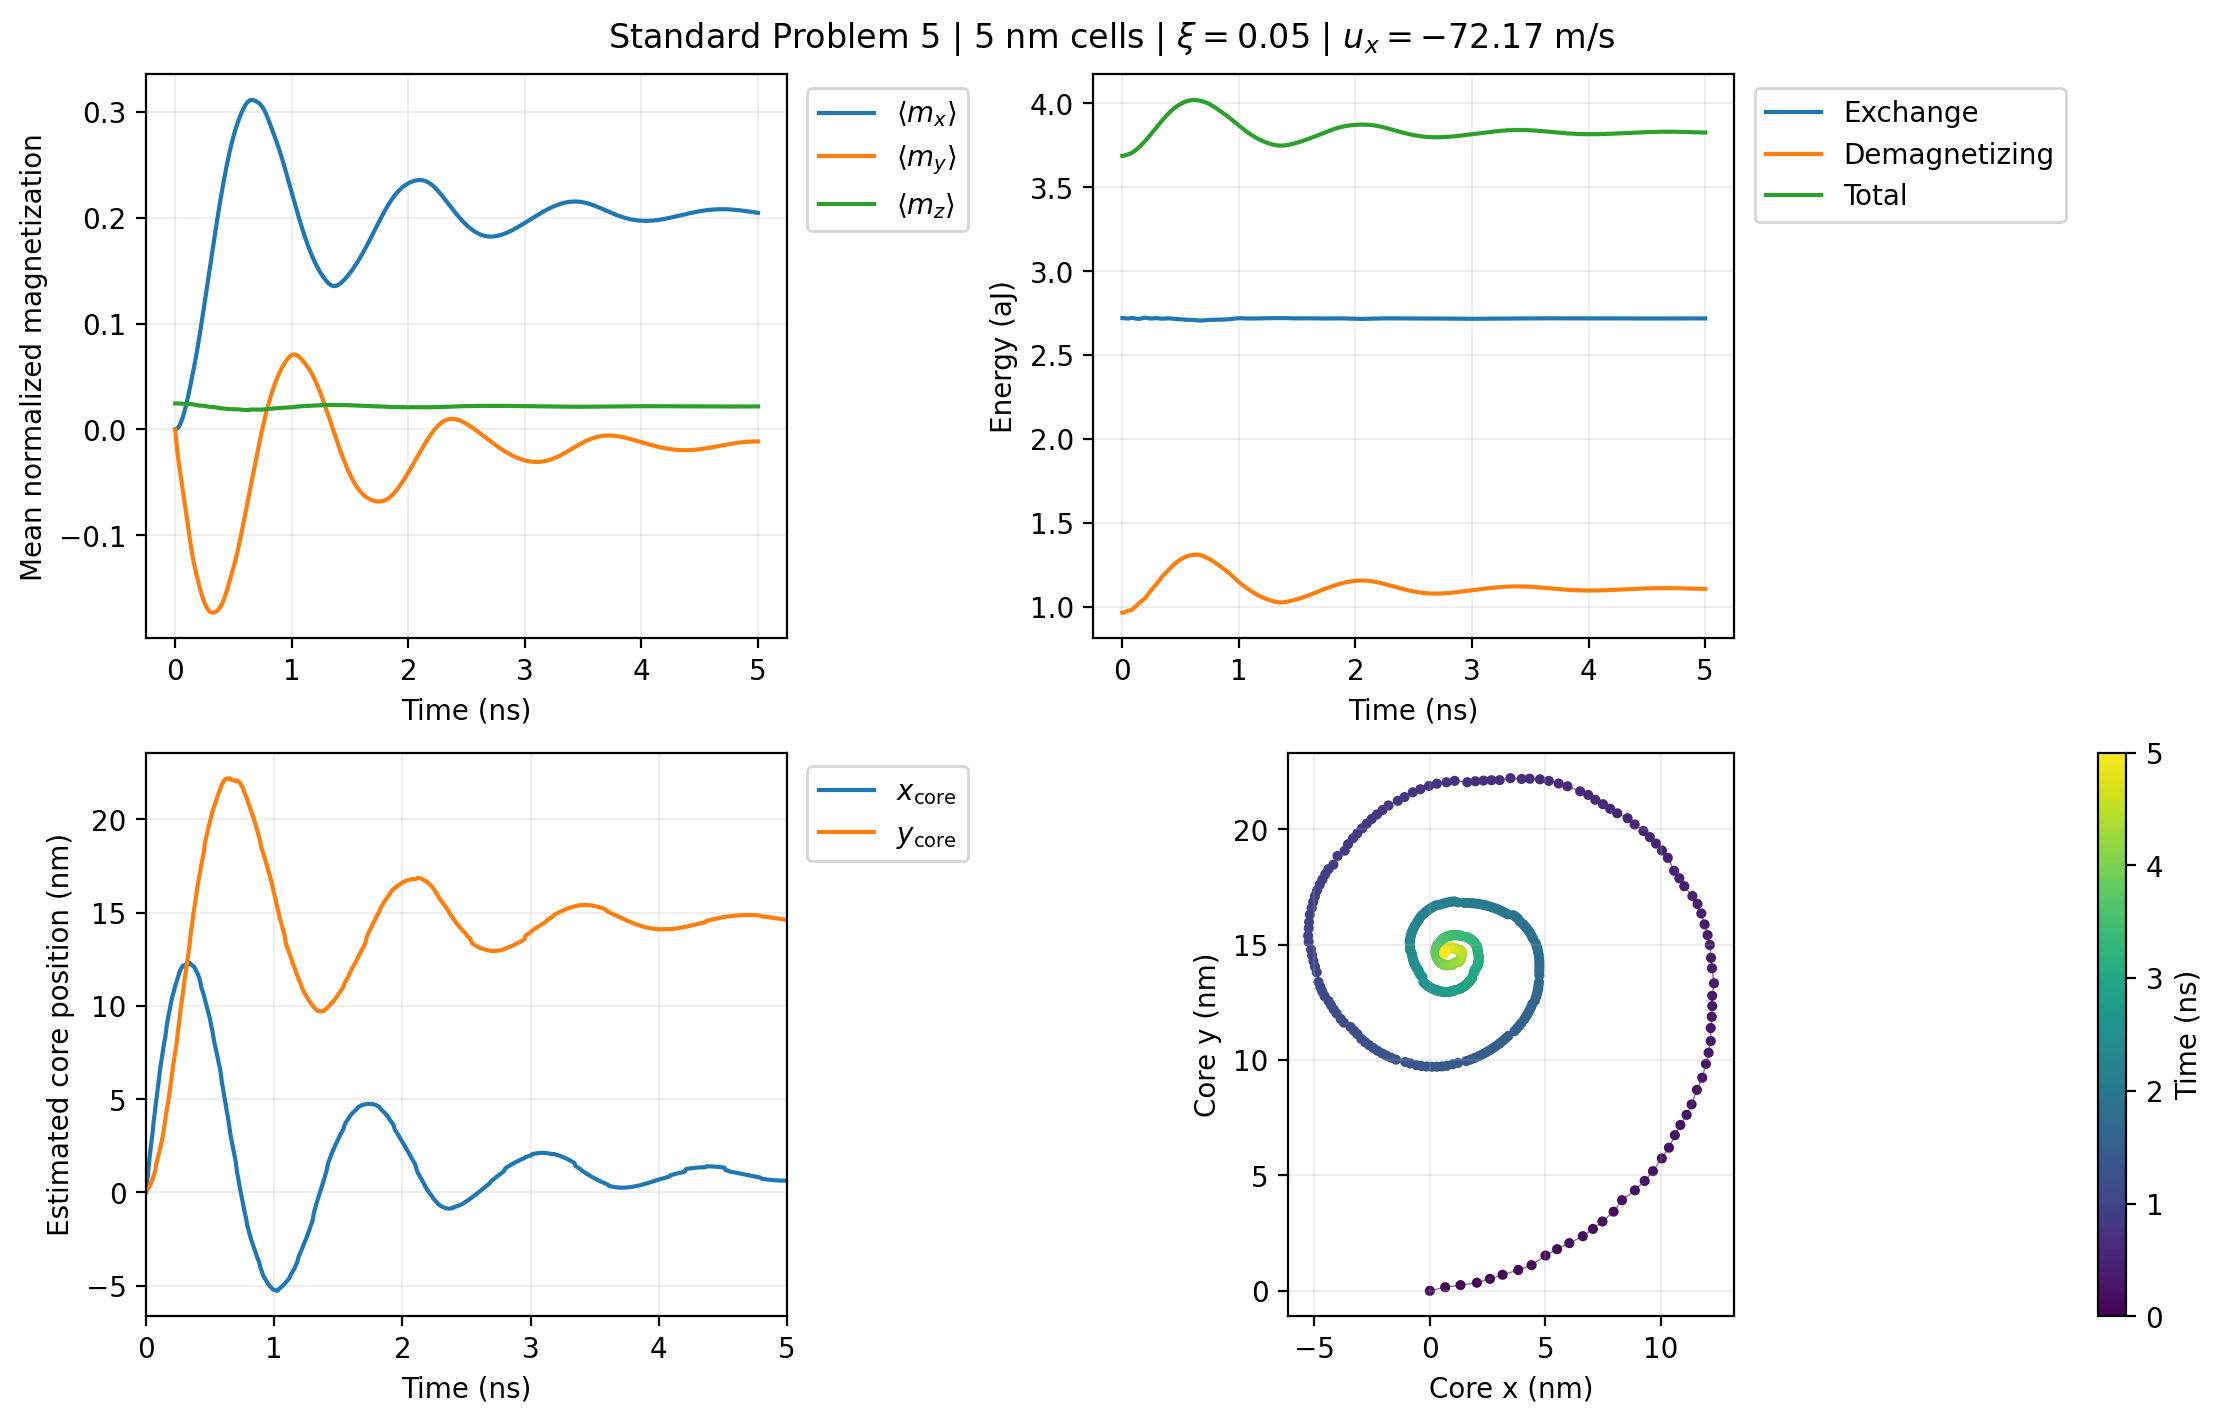

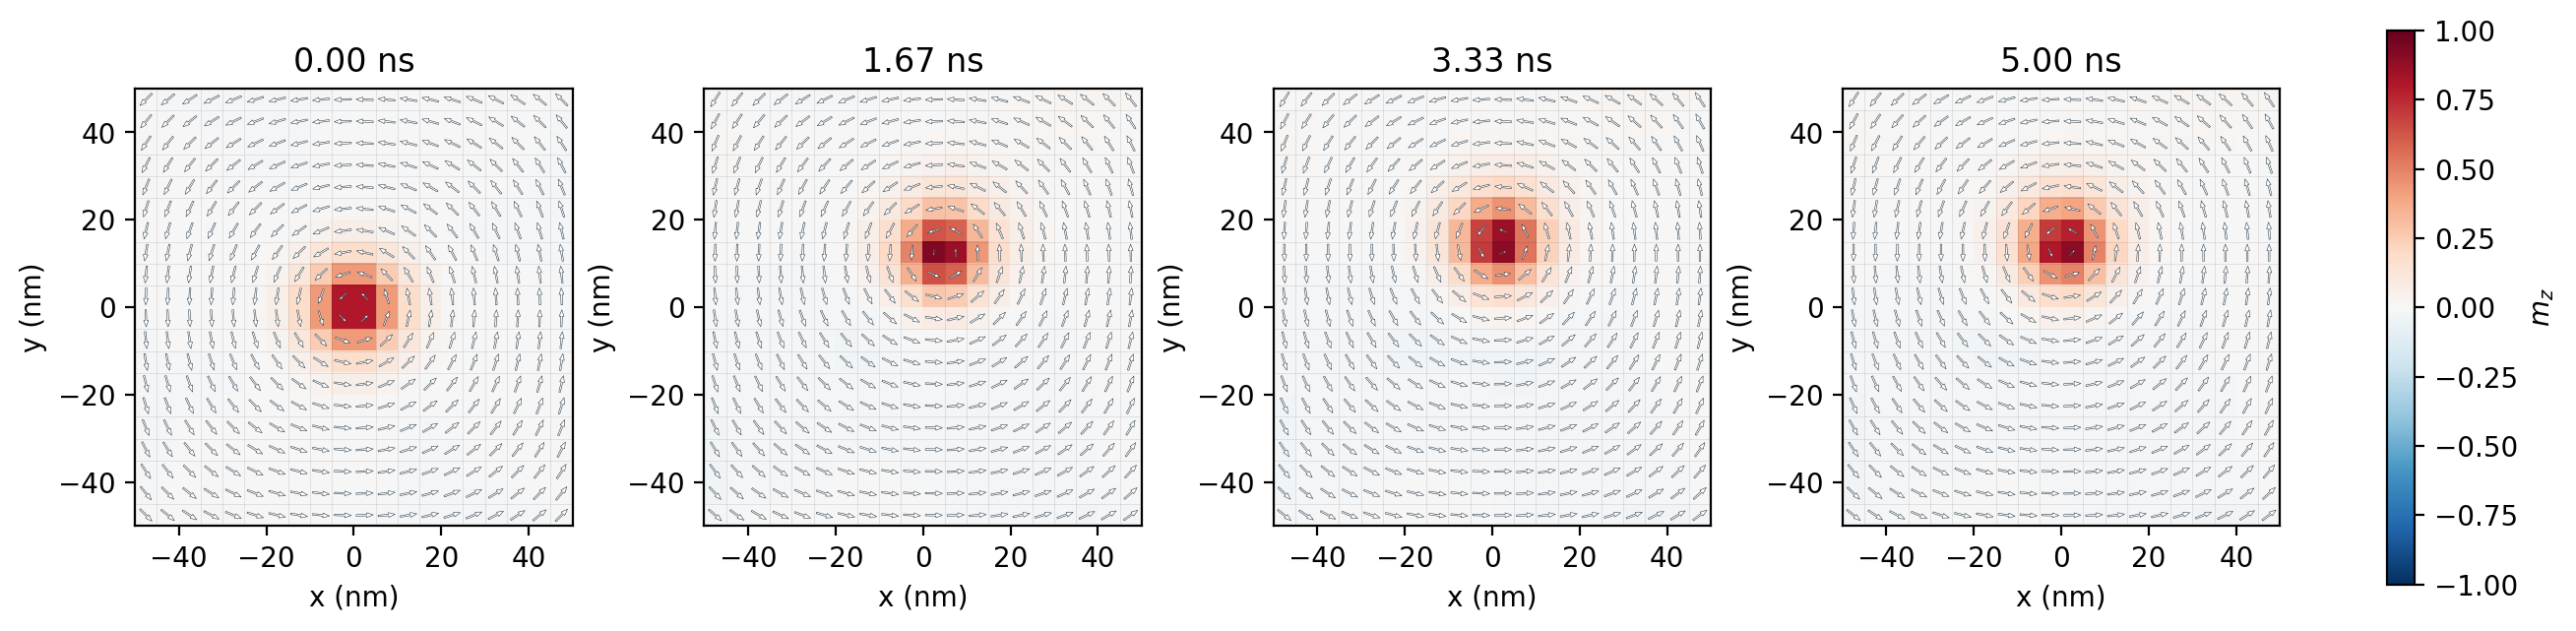

Final estimated core position (nm): [ 0.6301 14.61  ]
Frames with unavailable core position: 0


In [9]:
RESULT, LIBRARY = run_calculation(CFG)

## Animate the computed cells

In [ ]:
ANIMATION = animate_results(RESULT)

## Measure time-step and mesh sensitivity

In [11]:
REFINEMENTS = run_refinements(RESULT, LIBRARY)

Refinement controls are off.


## References

1. Najafi, M., Krüger, B., Bohlens, S., Franchin, M., Fangohr, H., Vanhaverbeke, A., Allenspach, R., Bolte, M., Merkt, U., Pfannkuche, D., Möller, D.P.F. and Meier, G. (2009) 'Proposal for a standard problem for micromagnetic simulations including spin-transfer torque', *Journal of Applied Physics*, 105, 113914. https://doi.org/10.1063/1.3126702
2. Zhang, S. and Li, Z. (2004) 'Roles of nonequilibrium conduction electrons on the magnetization dynamics of ferromagnets', *Physical Review Letters*, 93, 127204. https://doi.org/10.1103/PhysRevLett.93.127204
3. Newell, A.J., Williams, W. and Dunlop, D.J. (1993) 'A generalization of the demagnetizing tensor for nonuniform magnetization', *Journal of Geophysical Research: Solid Earth*, 98(B6), pp. 9551–9555. https://doi.org/10.1029/93JB00694
4. Alouges, F. (2008) 'A new finite element scheme for Landau-Lifchitz equations', *Discrete and Continuous Dynamical Systems, Series S*, 1(2), pp. 187–196. https://doi.org/10.3934/dcdss.2008.1.187

| Technical resource | Purpose |
|---|---|
| [NIST Standard Problem 5 specification](https://www.ctcms.nist.gov/~rdm/std5/spec5.xhtml) | Benchmark definition |
| [NIST submitted solutions](https://www.ctcms.nist.gov/~rdm/std5/Porter.html) | Published reference trajectories and signed current coefficients |
| [Authors' supporting material](https://fangohr.github.io/publications/2009-proposal-for-a-standard-problem-for-micromagnetic-simulations-including-spin-transfer-torque/index.html) | Current normalization correction in the accompanying OOMMF input |
| [CuPy installation documentation](https://docs.cupy.dev/en/stable/install.html) | CUDA component wheels and one CuPy distribution per environment |
| [CUDA header lookup](https://nvidia.github.io/cuda-python/cuda-pathfinder/latest/generated/cuda.pathfinder.find_nvidia_header_directory.html) | Installed-wheel header search order |
| [NVIDIA cuDSS documentation](https://docs.nvidia.com/cuda/cudss/latest/getting_started.html) | Installation, matrix wrappers, analysis, factorization, and solve phases |
| [Zhang–Li torque convention](https://ubermag.github.io/api/_autosummary/micromagneticmodel.ZhangLi.html) | Signed torque equation used for the current convention |

## Summary

This notebook computes a relaxed permalloy vortex and its current-driven dynamics through a three-dimensional finite-cell model, with cuDSS solving the magnetization update and CuPy evaluating the remaining GPU operators.